In [1]:
# Import pustaka yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [2]:
from pathlib import Path
# Membaca file Excel
file_path = Path.cwd().parent / "data" / "credit_risk_survey.xlsx"
df = pd.read_excel(file_path, sheet_name="Full Data")
indicators = pd.read_excel(file_path, sheet_name="Indicators")
dictionary = pd.read_excel(file_path, sheet_name="Sheet1")
scales = pd.read_excel(file_path, sheet_name="Sheet2")


In [3]:
# --- INFORMASI DASAR ---
print("===== Informasi Data =====")
print(df.info())
print("\nJumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

===== Informasi Data =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2700 entries, 0 to 2699
Columns: 204 entries, IDR to Y4.2.2
dtypes: float64(3), int64(200), object(1)
memory usage: 4.2+ MB
None

Jumlah baris: 2700
Jumlah kolom: 204


In [4]:
# --- CEK NILAI KOSONG ---
print("\n===== Nilai Kosong Tiap Kolom =====")
print(df.isnull().sum().sort_values(ascending=False))


===== Nilai Kosong Tiap Kolom =====
IDR        0
IDR1       0
No Bank    0
Nama       0
C11        0
          ..
X17.3.2    0
Y4.1.1     0
Y4.1.2     0
Y4.2.1     0
Y4.2.2     0
Length: 204, dtype: int64



===== Distribusi Data per Bank =====
Nama
Bank XE    800
Bank XA    500
Bank XB    500
Bank XC    500
Bank XD    400
Name: count, dtype: int64


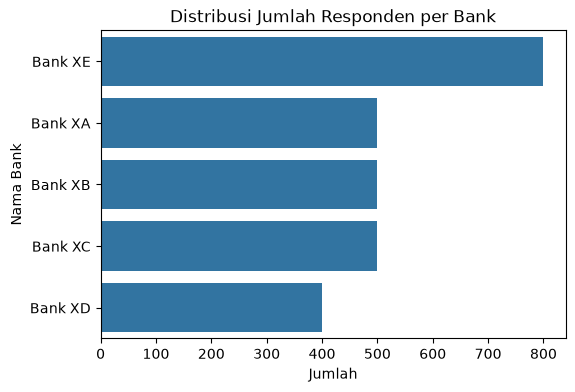

In [5]:
# --- SEBARAN BANK ---
print("\n===== Distribusi Data per Bank =====")
print(df["Nama"].value_counts())
plt.figure(figsize=(6,4))
sns.countplot(y="Nama", data=df, order=df["Nama"].value_counts().index)
plt.title("Distribusi Jumlah Responden per Bank")
plt.xlabel("Jumlah")
plt.ylabel("Nama Bank")
plt.show()

In [6]:
# Pastikan kolom target ada
target_col = 'Z (cat)'
if target_col not in df.columns:
    raise ValueError(f"Kolom '{target_col}' tidak ditemukan di data!")

<tmp>\ipykernel_31440\4112639643.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=df, palette='coolwarm')


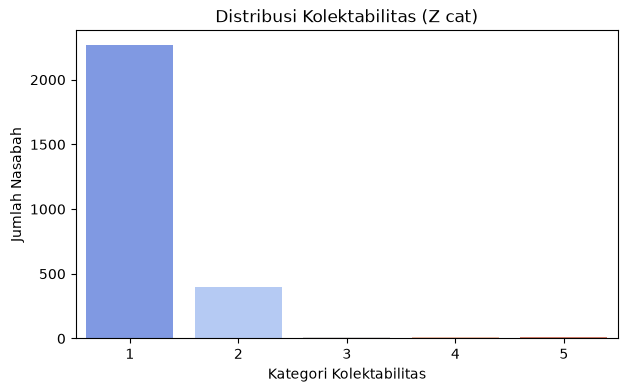

In [7]:
# --- 1. Distribusi Kolektabilitas (Z cat) ---
plt.figure(figsize=(7,4))
sns.countplot(x=target_col, data=df, palette='coolwarm')
plt.title('Distribusi Kolektabilitas (Z cat)')
plt.xlabel('Kategori Kolektabilitas')
plt.ylabel('Jumlah Nasabah')
plt.show()

<tmp>\ipykernel_31440\48177124.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")
<tmp>\ipykernel_31440\48177124.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")
<tmp>\ipykernel_31440\48177124.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")


<tmp>\ipykernel_31440\48177124.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")
<tmp>\ipykernel_31440\48177124.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")


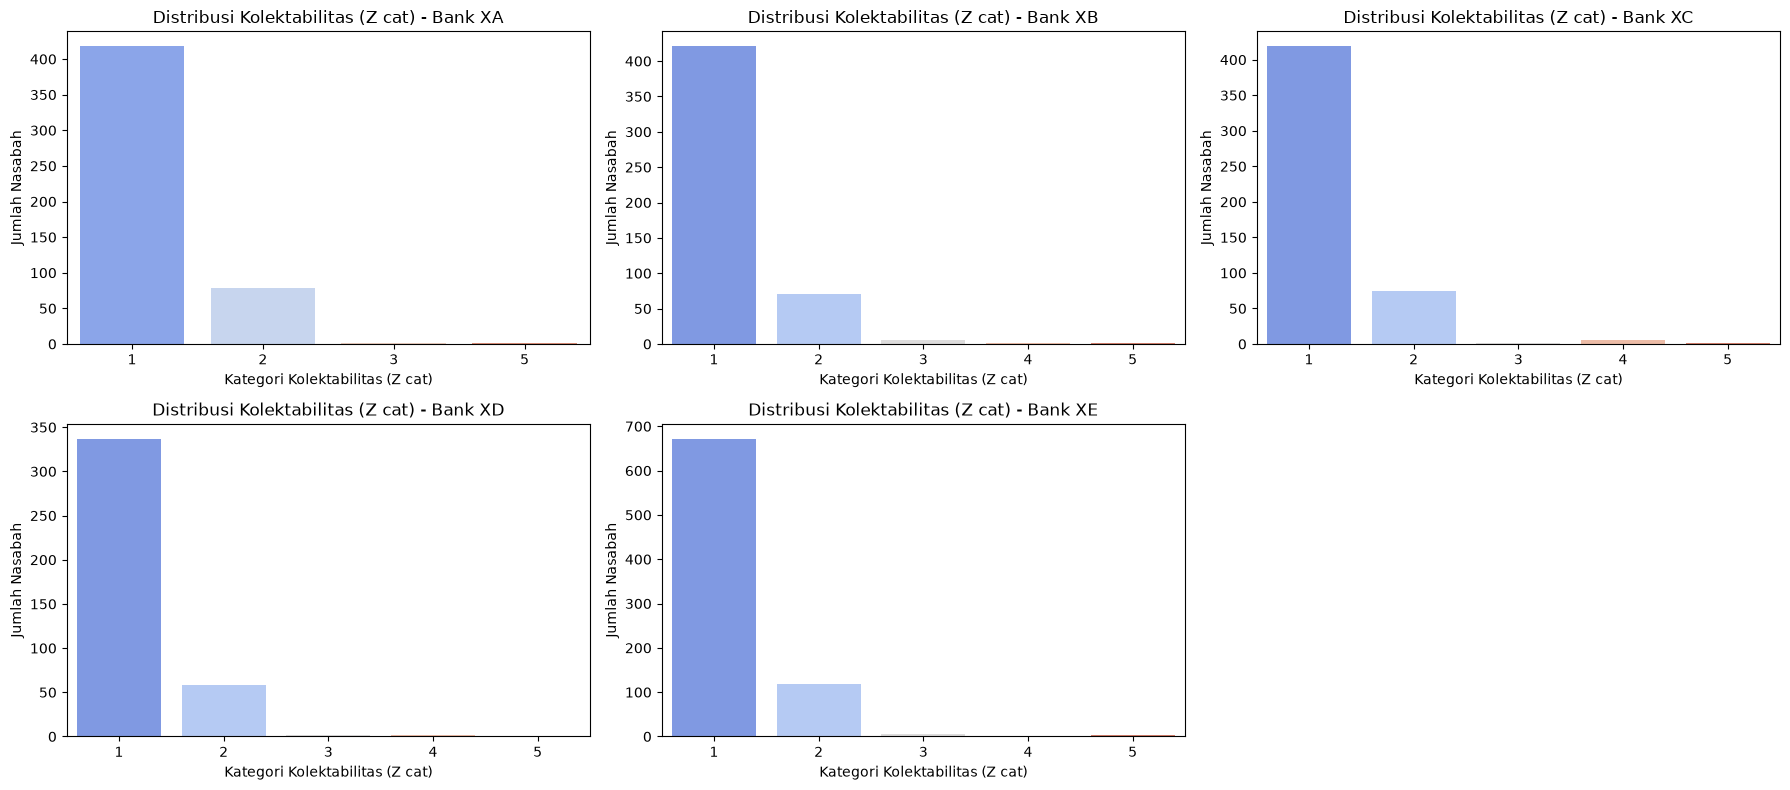

In [8]:
# --- Daftar semua bank ---
banks = sorted(df["Nama"].unique())
n_banks = len(banks)

# --- Tentukan grid ukuran (misalnya 3 kolom) ---
cols = 3
rows = math.ceil(n_banks / cols)

plt.figure(figsize=(6*cols, 4*rows))

# --- Plot untuk setiap bank ---
for i, bank in enumerate(banks, start=1):
    plt.subplot(rows, cols, i)
    subset = df[df["Nama"] == bank]
    sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")
    plt.title(f"Distribusi Kolektabilitas (Z cat) - {bank}")
    plt.xlabel("Kategori Kolektabilitas (Z cat)")
    plt.ylabel("Jumlah Nasabah")
    plt.tight_layout()

plt.show()

In [9]:
#Data cleaning
#Menyesuaikan target variabel
df["Z (cat)"].value_counts()
df["Z (cat)"] = np.where(df["Z (cat)"] <= 2, 1, 0)
df["Z (cat)"].value_counts()

Z (cat)
1    2667
0      33
Name: count, dtype: int64

In [10]:
#Drop kolom yang tidak akan digunakan
df = df.drop(columns=["IDR", "IDR1", "No Bank", "Nama", "Z (day)"], errors='ignore')


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [12]:
# --- Pisahkan fitur & target ---
X = df.drop(columns=["Z (cat)"])
y = df["Z (cat)"]

# --- Train-test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- Standarisasi optional ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [13]:
# =============================
# 1️⃣ LOGISTIC REGRESSION
# =============================
logreg = LogisticRegression(class_weight='balanced', max_iter=1000)
logreg.fit(X_train_scaled, y_train)
pred_logreg = logreg.predict(X_test_scaled)

print("\n=== Logistic Regression ===")
print(classification_report(y_test, pred_logreg))


=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.10      0.14      0.12         7
           1       0.99      0.98      0.99       533

    accuracy                           0.97       540
   macro avg       0.54      0.56      0.55       540
weighted avg       0.98      0.97      0.97       540



In [14]:
# =============================
# 2️⃣ RANDOM FOREST
# =============================
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced_subsample',
    random_state=42
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("\n=== Random Forest ===")
print(classification_report(y_test, pred_rf))


=== Random Forest ===
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.99      1.00      0.99       533

    accuracy                           0.99       540
   macro avg       0.49      0.50      0.50       540
weighted avg       0.97      0.99      0.98       540



<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [15]:
# =============================
# 3️⃣ XGBOOST
# =============================
ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=ratio,
    eval_metric="logloss"
    
)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)

print("\n=== XGBoost ===")
print(classification_report(y_test, pred_xgb))


=== XGBoost ===
              precision    recall  f1-score   support

           0       0.11      0.14      0.12         7
           1       0.99      0.98      0.99       533

    accuracy                           0.97       540
   macro avg       0.55      0.56      0.56       540
weighted avg       0.98      0.97      0.98       540



In [16]:
# =============================
# 4️⃣ SVM
# =============================
svm = SVC(class_weight='balanced', probability=True)
svm.fit(X_train_scaled, y_train)
pred_svm = svm.predict(X_test_scaled)

print("\n=== SVM ===")
print(classification_report(y_test, pred_svm))

<python>\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



=== SVM ===
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.99      1.00      0.99       533

    accuracy                           0.99       540
   macro avg       0.49      0.50      0.50       540
weighted avg       0.97      0.99      0.98       540



<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [17]:
# =============================
# 5️⃣ GRADIENT BOOSTING
# =============================
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)
pred_gb = gb.predict(X_test)

print("\n=== Gradient Boosting ===")
print(classification_report(y_test, pred_gb))


=== Gradient Boosting ===
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.99      1.00      0.99       533

    accuracy                           0.99       540
   macro avg       0.49      0.50      0.50       540
weighted avg       0.97      0.99      0.98       540



<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [18]:
# ============================
# HYBRID APPROACH:
# SMOTE + TOMEK LINKS
# ============================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from imblearn.combine import SMOTETomek
from xgboost import XGBClassifier

In [19]:
# -----------------------------
# 1. Pisahkan Fitur dan Target
# -----------------------------
X = df.drop(columns=["Z (cat)"])
y = df["Z (cat)"]

# Encoding untuk variabel kategorikal
X = pd.get_dummies(X, drop_first=True)

In [20]:
# -----------------------------
# 2. Train-test split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Sebelum SMOTE-Tomek:", np.bincount(y_train))

Sebelum SMOTE-Tomek: [  26 2134]


In [21]:
# -----------------------------
# 3. Hybrid Oversampling:
#    SMOTE + TomekLinks
# -----------------------------
smt = SMOTETomek(random_state=42)
X_res, y_res = smt.fit_resample(X_train, y_train)

print("Setelah SMOTE-Tomek:", np.bincount(y_res))


Setelah SMOTE-Tomek: [2134 2134]


In [22]:
# -----------------------------
# 4. Scaling (optional)
# -----------------------------
scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)
X_test_scaled = scaler.transform(X_test)


In [23]:
# -----------------------------
# 5. MODEL: XGBOOST
# -----------------------------
model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss"
)

# Train model
model.fit(X_res_scaled, y_res)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [24]:
# -----------------------------
# 6. Prediksi
# -----------------------------
y_pred = model.predict(X_test_scaled)

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred))

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred))


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.99      1.00      0.99       533

    accuracy                           0.99       540
   macro avg       0.49      0.50      0.50       540
weighted avg       0.97      0.99      0.98       540


===== CONFUSION MATRIX =====
[[  0   7]
 [  1 532]]


In [25]:
# -----------------------------
# 7. Threshold Tuning (optional)
# -----------------------------
probs = model.predict_proba(X_test_scaled)[:, 1]
threshold = 0.35  # recommended for imbalance
y_pred_thresh = (probs > threshold).astype(int)

print("\n===== REPORT (Threshold = 0.35) =====")
print(classification_report(y_test, y_pred_thresh))

print("\n===== CONFUSION MATRIX (Threshold 0.35) =====")
print(confusion_matrix(y_test, y_pred_thresh))


===== REPORT (Threshold = 0.35) =====
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.99      1.00      0.99       533

    accuracy                           0.99       540
   macro avg       0.49      0.50      0.50       540
weighted avg       0.97      0.99      0.98       540


===== CONFUSION MATRIX (Threshold 0.35) =====
[[  0   7]
 [  1 532]]


In [26]:
from imblearn.ensemble import BalancedRandomForestClassifier

model = BalancedRandomForestClassifier(
    n_estimators=500,
    random_state=42
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

[[  1   6]
 [  9 524]]
              precision    recall  f1-score   support

           0       0.10      0.14      0.12         7
           1       0.99      0.98      0.99       533

    accuracy                           0.97       540
   macro avg       0.54      0.56      0.55       540
weighted avg       0.98      0.97      0.97       540



In [27]:
from imblearn.ensemble import RUSBoostClassifier

model = RUSBoostClassifier(random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

[[  6   1]
 [256 277]]
              precision    recall  f1-score   support

           0       0.02      0.86      0.04         7
           1       1.00      0.52      0.68       533

    accuracy                           0.52       540
   macro avg       0.51      0.69      0.36       540
weighted avg       0.98      0.52      0.67       540



In [28]:
ratio = len(y[y==1]) / len(y[y==0])
print("Ratio:", ratio)
model = XGBClassifier(
    scale_pos_weight = ratio,
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    eval_metric="logloss"
)

Ratio: 80.81818181818181


In [29]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [31]:
models_and_params = {

    "LogisticRegression": (
        Pipeline([
            ("scale", StandardScaler()),
            ("smt", SMOTETomek(random_state=42)),
            ("clf", LogisticRegression(max_iter=1000))
        ]),
        {
            "clf__C": [0.01, 0.1, 1, 10],
            "clf__penalty": ['l2'],
            "clf__solver": ['lbfgs']
        }
    ),

    "RandomForest": (
        Pipeline([
            ("smt", SMOTETomek(random_state=42)),
            ("clf", RandomForestClassifier())
        ]),
        {
            "clf__n_estimators": [100, 200, 300],
            "clf__max_depth": [None, 10, 20],
            "clf__min_samples_split": [2, 5],
        }
    ),

    "XGBoost": (
        Pipeline([
            ("smt", SMOTETomek(random_state=42)),
            ("clf", XGBClassifier(eval_metric='logloss'))
        ]),
        {
            "clf__n_estimators": [200, 300],
            "clf__max_depth": [3, 5, 7],
            "clf__learning_rate": [0.01, 0.1],
            "clf__subsample": [0.8, 1.0]
        }
    ),

    "SVM": (
        Pipeline([
            ("scale", StandardScaler()),
            ("smt", SMOTETomek(random_state=42)),
            ("clf", SVC())
        ]),
        {
            "clf__C": [0.1, 1, 10],
            "clf__kernel": ['rbf', 'linear'],
            "clf__gamma": ['scale', 'auto']
        }
    ),

    "KNN": (
        Pipeline([
            ("scale", StandardScaler()),
            ("smt", SMOTETomek(random_state=42)),
            ("clf", KNeighborsClassifier())
        ]),
        {
            "clf__n_neighbors": [3, 5, 7, 9],
            "clf__weights": ['uniform', 'distance'],
        }
    ),

}

In [32]:
results = {}

for name, (pipeline, params) in models_and_params.items():
    print(f"\n==============================")
    print(f"Training Model: {name}")
    print("==============================")
    
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        cv=3,
        scoring='f1',
        n_jobs=-1
    )
    
    grid.fit(X_train, y_train)
    
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    
    print("\nBest Params:", grid.best_params_)
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    results[name] = {
        "best_model": best_model,
        "best_params": grid.best_params_
    }


Training Model: LogisticRegression


<python>\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



Best Params: {'clf__C': 1, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}

Confusion Matrix:
 [[  1   6]
 [  8 525]]

Classification Report:
               precision    recall  f1-score   support

           0       0.11      0.14      0.12         7
           1       0.99      0.98      0.99       533

    accuracy                           0.97       540
   macro avg       0.55      0.56      0.56       540
weighted avg       0.98      0.97      0.98       540


Training Model: RandomForest



Best Params: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 100}

Confusion Matrix:
 [[  0   7]
 [  0 533]]

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.99      1.00      0.99       533

    accuracy                           0.99       540
   macro avg       0.49      0.50      0.50       540
weighted avg       0.97      0.99      0.98       540


Training Model: XGBoost


<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



Best Params: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 200, 'clf__subsample': 1.0}

Confusion Matrix:
 [[  0   7]
 [  1 532]]

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.99      1.00      0.99       533

    accuracy                           0.99       540
   macro avg       0.49      0.50      0.50       540
weighted avg       0.97      0.99      0.98       540


Training Model: SVM



Best Params: {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}

Confusion Matrix:
 [[  0   7]
 [  0 533]]

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.99      1.00      0.99       533

    accuracy                           0.99       540
   macro avg       0.49      0.50      0.50       540
weighted avg       0.97      0.99      0.98       540


Training Model: KNN


<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



Best Params: {'clf__n_neighbors': 3, 'clf__weights': 'uniform'}

Confusion Matrix:
 [[  7   0]
 [503  30]]

Classification Report:
               precision    recall  f1-score   support

           0       0.01      1.00      0.03         7
           1       1.00      0.06      0.11       533

    accuracy                           0.07       540
   macro avg       0.51      0.53      0.07       540
weighted avg       0.99      0.07      0.11       540

